# Analysis of Ambuja Cement (AMBUJACEM.BSE) Stock Volatility Using Log Returns and Rolling Volatility

1. Import & aktivasi mock

Mengimpor requests, pandas, dan modul mock_alpha. activate_mock() mencegat requests.get sehingga panggilan API Alpha Vantage tidak benar-benar keluar ke internet.

In [1]:
import requests
import pandas as pd
from mock_alpha import activate_mock, deactivate_mock

# Start intercepting requests.get
activate_mock()

2. Request data “compact”

Membangun URL Alpha Vantage (TIME_SERIES_DAILY) untuk ticker AMBUJACEM.BSE dengan outputsize=compact, lalu memvalidasi status 200 dan jumlah data tepat 100 hari.

In [2]:
# Build the URL with query parameters
ticker = "AMBUJACEM.BSE"
output_size = "compact"
url = (
    "https://www.alphavantage.co/query?"
    "function=TIME_SERIES_DAILY&"
    f"symbol={ticker}&"
    f"outputsize={output_size}&"
    "datatype=json&"
    "apikey=demo"  # in a real project, you would use your own API key
)

# Send the GET request (intercepted by the mock)
response = requests.get(url)
print("Status code:", response.status_code)

data = response.json()
n_days = len(data["Time Series (Daily)"])
print(f"outputsize='{output_size}' returned {n_days} days")
assert n_days == 100

Status code: 200
outputsize='compact' returned 100 days


3. Request data “full”

Sama seperti sel 2, tetapi outputsize=full. Hasilnya 5.225 hari data, dan assert memastikan jumlahnya > 2000.

In [3]:
output_size = "full"
url = (
    "https://www.alphavantage.co/query?"
    "function=TIME_SERIES_DAILY&"
    f"symbol={ticker}&"
    f"outputsize={output_size}&"
    "datatype=json&"
    "apikey=demo"
)

response = requests.get(url)
data = response.json()
n_days = len(data["Time Series (Daily)"])
print(f"outputsize='{output_size}' returned {n_days} days")
assert n_days > 2000

outputsize='full' returned 5225 days


4. Konversi JSON ke DataFrame

Mengubah dictionary Time Series (Daily) menjadi DataFrame bertipe float, mengubah indeks menjadi DatetimeIndex bernama date, merapikan nama kolom ("1. open" → open), dan mengurutkan dari tanggal terlama ke terbaru.

In [4]:
# Parse JSON into a dictionary
data = response.json()

# Extract the time series portion
stock_data = data["Time Series (Daily)"]

# Convert to DataFrame (values arrive as strings)
df = pd.DataFrame.from_dict(
    stock_data, orient="index", dtype=float
)

# Fix the index: convert to DatetimeIndex, name it
df.index = pd.to_datetime(df.index)
df.index.name = "date"

# Clean column names: "1. open" -> "open"
df.columns = [c.split(". ")[1] for c in df.columns]

# Sort chronologically (API returns newest first)
df.sort_index(inplace=True)

print(df.dtypes)
df

open      float64
high      float64
low       float64
close     float64
volume    float64
dtype: object


,open,high,low,close,volume
date,,,,,
2005-01-03,405.0001,409.5001,403.1001,407.6001,1061050.0
2005-01-04,410.0001,429.0001,409.0001,425.8501,2501549.0
2005-01-05,427.0001,439.9001,406.1501,425.9501,3537669.0
2005-01-06,426.0001,431.0001,412.0001,416.0501,3103853.0
2005-01-07,420.0001,428.5001,418.0001,426.3001,2330736.0
...,...,...,...,...,...
2026-03-16,425.1000,435.0000,424.8000,428.3500,155843.0
2026-03-17,430.8000,436.2000,428.1000,433.9500,253700.0
2026-03-18,438.4500,444.0000,433.9000,441.1500,60332.0


5. Simpan ke CSV

Menyimpan DataFrame ke data/ambuja_cement.csv agar notebook berikutnya tidak bergantung pada API.

In [5]:
# Save to CSV so downstream notebooks work from
# a flat file instead of the API
df.to_csv("data/ambuja_cement.csv")
print("Saved to data/ambuja_cement.csv. Shape:", df.shape)

Saved to data/ambuja_cement.csv. Shape: (5225, 5)


6. Nonaktifkan mock

deactivate_mock() mengembalikan perilaku normal requests.

In [6]:
# Deactivate the mock — restore normal requests behavior
deactivate_mock()

7. Deret harga (dummy)

Membuat pd.Series 5 hari harga penutupan untuk demonstrasi konsep.

In [7]:
import numpy as np
import pandas as pd

# Toy price series: 5 days of closing prices
prices = pd.Series(
    [100.0, 102.0, 99.0, 101.5, 103.0],
    index=pd.date_range("2025-01-06", periods=5, freq="B"),
    name="close",
)
prices.index.name = "date"
print("Price series:")
print(prices)

Price series:
date
2025-01-06    100.0
2025-01-07    102.0
2025-01-08     99.0
2025-01-09    101.5
2025-01-10    103.0
Freq: B, Name: close, dtype: float64


8. Simple return

Menghitung return sederhana dengan pct_change().

In [8]:
# Simple returns using pct_change
simple_returns = prices.pct_change()
print("Simple returns:")
print(simple_returns)

Simple returns:
date
2025-01-06         NaN
2025-01-07    0.020000
2025-01-08   -0.029412
2025-01-09    0.025253
2025-01-10    0.014778
Freq: B, Name: close, dtype: float64


9. Log return (dummy)

Menghitung log return dengan np.log(prices / prices.shift(1)).

In [9]:
# Log returns using numpy
log_returns = np.log(prices / prices.shift(1))
print("Log returns:")
print(log_returns)

Log returns:
date
2025-01-06         NaN
2025-01-07    0.019803
2025-01-08   -0.029853
2025-01-09    0.024939
2025-01-10    0.014670
Freq: B, Name: close, dtype: float64


10. Simulasi dua rezim volatilitas

Membangkitkan 500 return sintetis: 250 hari volatilitas rendah (σ=0,005) dan 250 hari volatilitas tinggi (σ=0,025), lalu diplot untuk menunjukkan perubahan volatilitas.

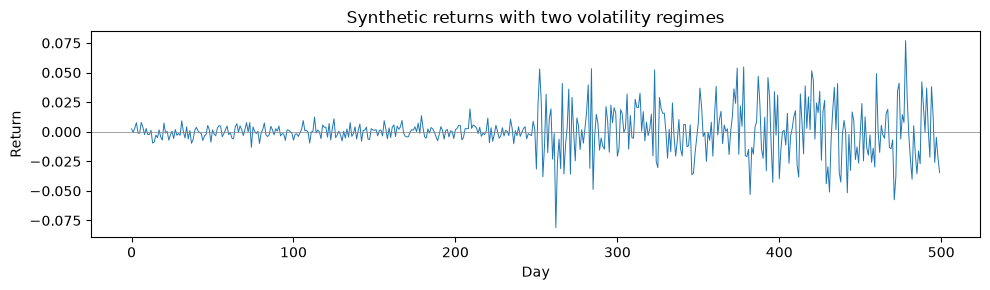

In [10]:
import matplotlib.pyplot as plt

np.random.seed(42)
n = 500

# Simulate two regimes: low-vol and high-vol
low_vol = np.random.normal(0, 0.005, n // 2)
high_vol = np.random.normal(0, 0.025, n // 2)
synthetic_returns = np.concatenate([low_vol, high_vol])

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(synthetic_returns, linewidth=0.7)
ax.set_title("Synthetic returns with two volatility regimes")
ax.set_xlabel("Day")
ax.set_ylabel("Return")
ax.axhline(0, color="gray", linewidth=0.5)
plt.tight_layout()
plt.show()

11. Demo read_csv

Membaca CSV dari string (StringIO) dengan parse_dates dan index_col untuk menunjukkan cara memuat data deret waktu.

In [11]:
from io import StringIO

csv_text = """\
date,close,volume
2025-01-06,100.00,1500000
2025-01-07,102.00,1600000
2025-01-08,99.00,1750000
"""

df_demo = pd.read_csv(
    StringIO(csv_text),
    parse_dates=["date"],
    index_col="date",
)
print(df_demo.dtypes)
df_demo

close     float64
volume      int64
dtype: object


,close,volume
date,,
2025-01-06,100.0,1500000
2025-01-07,102.0,1600000
2025-01-08,99.0,1750000


12. info() dan shape

Memeriksa ukuran, tipe data, dan nilai kosong dalam sekali lihat.

In [12]:
# Shape, dtypes, and missing values in one glance
print("Shape:", df_demo.shape)
print()
df_demo.info()

Shape: (3, 2)

<class 'pandas.DataFrame'>
DatetimeIndex: 3 entries, 2025-01-06 to 2025-01-08
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   close   3 non-null      float64
 1   volume  3 non-null      int64  
dtypes: float64(1), int64(1)
memory usage: 72.0 bytes


13. describe()

Menampilkan statistik ringkas kolom numerik.

In [13]:
# Summary statistics for numeric columns
df_demo.describe()

,close,volume
count,3.000000,3.000000e+00
mean,100.333333,1.616667e+06
std,1.527525,1.258306e+05
min,99.000000,1.500000e+06
25%,99.500000,1.550000e+06
50%,100.000000,1.600000e+06
75%,101.000000,1.675000e+06
max,102.000000,1.750000e+06


14. Plot harga dan log return (dummy)

Dua panel: garis harga di atas, bar log return di bawah.

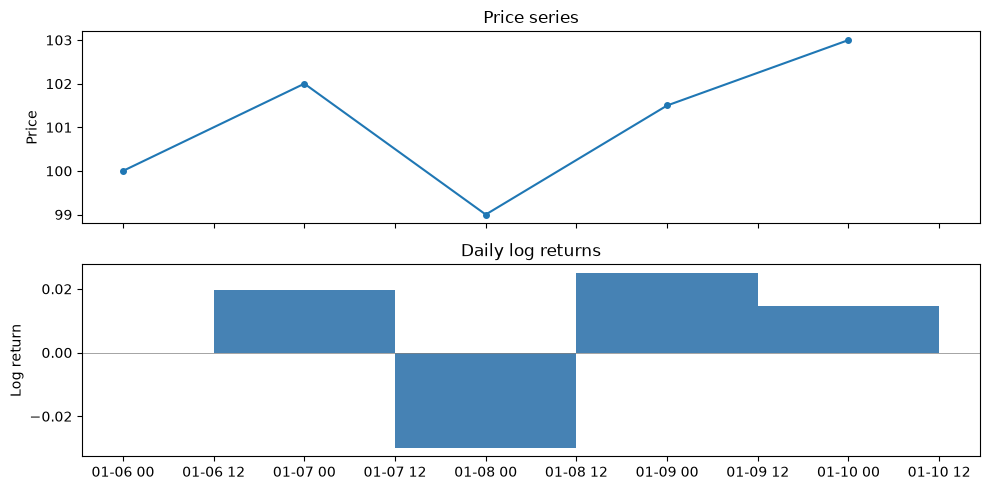

In [14]:
fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)

# Price chart
axes[0].plot(prices, marker="o", markersize=4)
axes[0].set_ylabel("Price")
axes[0].set_title("Price series")

# Return chart (log returns)
axes[1].bar(
    log_returns.dropna().index,
    log_returns.dropna().values,
    width=1,
    color="steelblue",
)
axes[1].set_ylabel("Log return")
axes[1].set_title("Daily log returns")
axes[1].axhline(0, color="gray", linewidth=0.5)

plt.tight_layout()
plt.show()

15. Import ulang library

Merapikan import utama: matplotlib, numpy, pandas, requests.

In [15]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests

16. Muat data Ambuja dari CSV

Membaca data/ambuja_cement.csv ke df_ambuja (5.225 baris × 5 kolom).

In [16]:
df_ambuja = pd.read_csv(
    "data/ambuja_cement.csv",
    index_col="date",
    parse_dates=["date"]
)
print(df_ambuja.shape)
print(df_ambuja.head())


(5225, 5)
                open      high       low     close     volume
date                                                         
2005-01-03  405.0001  409.5001  403.1001  407.6001  1061050.0
2005-01-04  410.0001  429.0001  409.0001  425.8501  2501549.0
2005-01-05  427.0001  439.9001  406.1501  425.9501  3537669.0
2005-01-06  426.0001  431.0001  412.0001  416.0501  3103853.0
2005-01-07  420.0001  428.5001  418.0001  426.3001  2330736.0


17. df_ambuja.info()

Memastikan 5.225 baris tanpa nilai kosong, semua kolom bertipe float64.

In [17]:
df_ambuja.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 5225 entries, 2005-01-03 to 2026-03-20
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   open    5225 non-null   float64
 1   high    5225 non-null   float64
 2   low     5225 non-null   float64
 3   close   5225 non-null   float64
 4   volume  5225 non-null   float64
dtypes: float64(5)
memory usage: 244.9 KB


18. df.sort_index()

Mengurutkan indeks. Catatan: baris ini mengurutkan df, bukan df_ambuja; hasilnya tetap aman karena CSV sudah terurut.

In [18]:
df.sort_index(inplace=True)

19. Checkpoint data

Assert memastikan indeks bertipe DatetimeIndex, terurut naik, tidak kosong, dan memiliki kolom close. Rentang data: 2005-01-03 s.d. 2026-03-20.

In [19]:
assert isinstance(df_ambuja.index, pd.DatetimeIndex), (
    f"Expected DatetimeIndex, got {type(df_ambuja.index).__name__}"
)
assert df_ambuja.index.is_monotonic_increasing, (
    "Index is not sorted in ascending order. "
    "Call df_ambuja.sort_index(inplace=True)."
)
assert df_ambuja.shape[0] > 0, "DataFrame is empty."
assert "close" in df_ambuja.columns, (
    f"Expected a 'close' column. Found: {df_ambuja.columns.tolist()}"
)
print(
    f"Checkpoint passed. "
    f"Shape: {df_ambuja.shape}, "
    f"Date range: {df_ambuja.index.min().date()} to "
    f"{df_ambuja.index.max().date()}"
)

Checkpoint passed. Shape: (5225, 5), Date range: 2005-01-03 to 2026-03-20


20. Ambil harga penutupan

close = df_ambuja["close"] menghasilkan Series 5.225 nilai.

In [20]:
close = df_ambuja["close"]
print("close shape:", close.shape)
close.head(5)

close shape: (5225,)


date
2005-01-03    407.6001
2005-01-04    425.8501
2005-01-05    425.9501
2005-01-06    416.0501
2005-01-07    426.3001
Name: close, dtype: float64

21. Hitung log return

np.log(close / close.shift(1)) lalu dropna() → 5.224 nilai log return.

In [21]:
log_returns = np.log(close / close.shift(1))
log_returns.name = 'log_return'
log_returns = log_returns.dropna()
print("log_returns shape:", log_returns.shape)
log_returns.head(5)

log_returns shape: (5224,)


date
2005-01-04    0.043801
2005-01-05    0.000235
2005-01-06   -0.023517
2005-01-07    0.024338
2005-01-10   -0.020500
Name: log_return, dtype: float64

22. Checkpoint log return

Memastikan tidak ada NaN/inf dan panjangnya len(close) - 1. Hasil: mean ≈ 0,000006, std ≈ 0,035157.

In [22]:
assert log_returns.isna().sum() == 0, (
    f"log_returns still has {log_returns.isna().sum()} NaN values."
)
expected_len = len(close) - 1
assert len(log_returns) == expected_len, (
    f"Expected {expected_len} returns, got {len(log_returns)}."
)
assert not np.isinf(log_returns).any(), (
    "log_returns contains inf values. Check for zero prices."
)
print(
    f"Checkpoint passed. "
    f"{len(log_returns)} log returns, "
    f"mean={log_returns.mean():.6f}, "
    f"std={log_returns.std():.6f}"
)

Checkpoint passed. 5224 log returns, mean=0.000006, std=0.035157


23. Visualisasi harga & log return Ambuja

Panel atas: harga penutupan; panel bawah: bar log return harian.

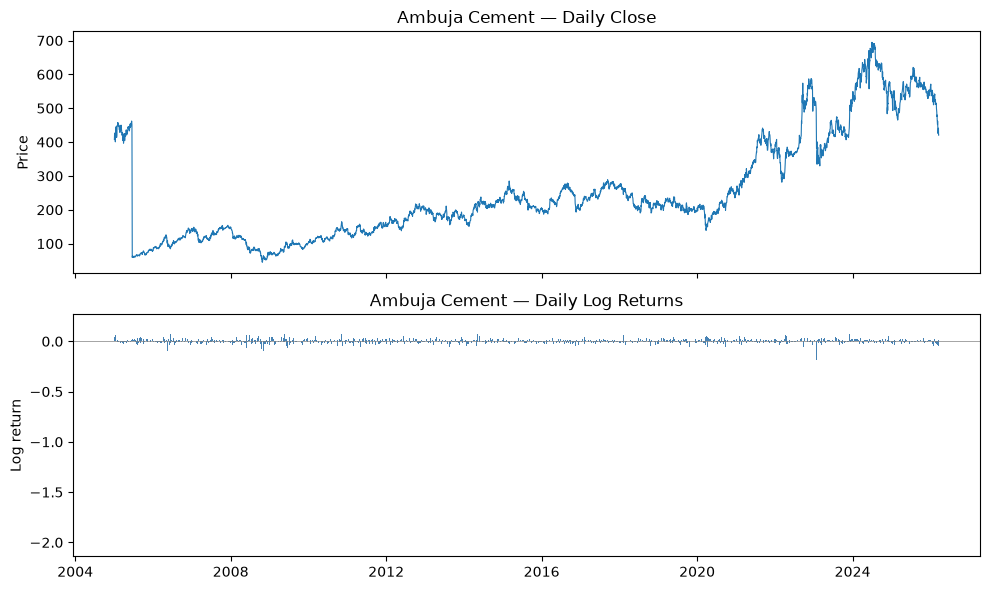

In [23]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

axes[0].plot(close, linewidth=0.8)
axes[0].set_ylabel("Price")
axes[0].set_title("Ambuja Cement — Daily Close")

axes[1].bar(
    log_returns.index,
    log_returns.values,
    width=2,
    color="steelblue",
)
axes[1].set_ylabel("Log return")
axes[1].set_title("Ambuja Cement — Daily Log Returns")
axes[1].axhline(0, color="gray", linewidth=0.5)

plt.tight_layout()
plt.show()

24. Checkpoint visual

Memastikan data cukup (>50 observasi) dan mengajak memeriksa volatility clustering, yaitu pergerakan besar cenderung diikuti pergerakan besar.

In [24]:
# Visual checkpoint — no assertion needed for plots.
# Verify the objects exist and have the right structure.
assert len(log_returns) > 50, (
    f"Only {len(log_returns)} returns — expected at least 50 "
    f"for a meaningful visualization."
)
print(
    "Checkpoint passed. Inspect the plots above: "
    "do you see periods where returns cluster together "
    "(large moves followed by large moves)?"
)

Checkpoint passed. Inspect the plots above: do you see periods where returns cluster together (large moves followed by large moves)?


25. describe() log return

Statistik ringkas: min −2,0296 (sangat ekstrem) dan max 0,1578.

In [25]:
log_returns.describe()

count    5224.000000
mean        0.000006
std         0.035157
min        -2.029634
25%        -0.010592
50%         0.000658
75%         0.011386
max         0.157777
Name: log_return, dtype: float64

26. Skewness & kurtosis

Skewness = −36,91 dan excess kurtosis = 2.127,42, menandakan distribusi sangat menceng ke kiri dengan ekor sangat tebal.

In [26]:
skew = log_returns.skew()
kurt = log_returns.kurtosis()
print(f"Skewness:       {skew:.4f}")
print(f"Excess kurtosis: {kurt:.4f}")

Skewness:       -36.9129
Excess kurtosis: 2127.4164


27. Checkpoint skew/kurt

Memastikan keduanya bertipe float dan menegaskan bahwa kurtosis > 0 berarti ekor tebal (heavy tails).

In [27]:
assert isinstance(skew, float), (
    f"Expected skew to be a float, got {type(skew).__name__}."
)
assert isinstance(kurt, float), (
    f"Expected kurt to be a float, got {type(kurt).__name__}."
)
print(
    f"Checkpoint passed. "
    f"Skewness={skew:.4f}, Excess kurtosis={kurt:.4f}. "
    f"Kurtosis > 0 suggests heavy tails."
)

Checkpoint passed. Skewness=-36.9129, Excess kurtosis=2127.4164. Kurtosis > 0 suggests heavy tails.


28. Rolling volatility 21 hari

Menghitung standar deviasi bergulir 21 hari (±1 bulan perdagangan), lalu memplot log return dan rolling volatility berdampingan.

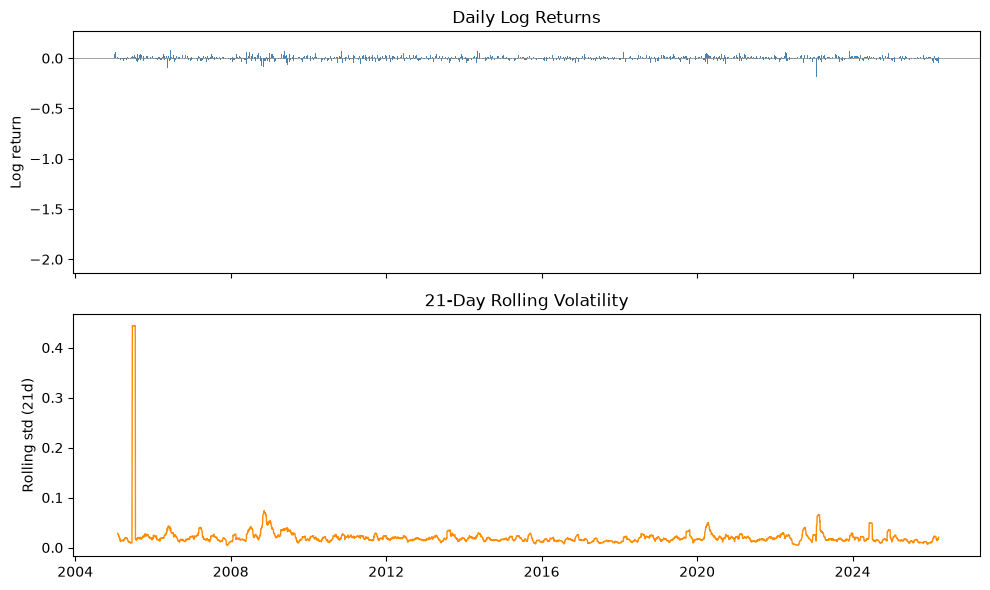

In [28]:
rolling_vol = log_returns.rolling(window=21).std()
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
axes[0].bar(
    log_returns.index,
    log_returns.values,
    width=2,
    color="steelblue",
)
axes[0].set_ylabel("Log return")
axes[0].set_title("Daily Log Returns")
axes[0].axhline(0, color="gray", linewidth=0.5)
axes[1].plot(rolling_vol, color="darkorange", linewidth=1)
axes[1].set_ylabel("Rolling std (21d)")
axes[1].set_title("21-Day Rolling Volatility")
plt.tight_layout()
plt.show()

29. Checkpoint rolling vol

Memastikan ada tepat 20 NaN awal (akibat window 21). Rolling vol maksimum 0,4445 dan minimum 0,0044.

In [29]:
assert rolling_vol is not None, "rolling_vol was not created."
# The first 20 values should be NaN (window=21 needs 21 points)
n_nan = rolling_vol.isna().sum()
assert n_nan == 20, (
    f"Expected 20 NaN values at the start of rolling_vol, "
    f"got {n_nan}. Check your window size."
)
print(
    f"Checkpoint passed. "
    f"Rolling volatility has {len(rolling_vol)} values "
    f"({n_nan} leading NaNs from the 21-day window). "
    f"Max rolling vol: {rolling_vol.max():.6f}, "
    f"min: {rolling_vol.min():.6f}."
)

Checkpoint passed. Rolling volatility has 5224 values (20 leading NaNs from the 21-day window). Max rolling vol: 0.444477, min: 0.004377.


Kesimpulan Singkat

- Data berhasil dibangun dan divalidasi. 
- Data harian Ambuja Cement 2005–2026 (5.225 observasi) diambil dari API (mock), dibersihkan, disimpan ke CSV, dan lolos semua checkpoint.
- Return rata-rata hampir nol, tetapi risikonya tinggi. 
- Mean log return ≈ 0,000006 dengan standar deviasi ≈ 0,035. 
- Pergerakan harian tidak berarah jelas, namun sebarannya besar.
- Distribusi return jauh dari normal. 
- Skewness −36,9 dan excess kurtosis ≈ 2.127 menunjukkan ekor sangat tebal. 
- Nilai minimum log return sekitar −2,03 (penurunan harian ±87%) kemungkinan besar bukan pergerakan pasar biasa, melainkan anomali data, misalnya efek stock split, corporate action, atau data yang belum disesuaikan. 
- Ini perlu diselidiki lebih lanjut sebelum pemodelan.
- Volatilitas tidak konstan. 
- Rolling volatility 21 hari berkisar dari 0,0044 hingga 0,4445, sehingga ada periode tenang dan periode bergejolak. 
- Ini mengindikasikan volatility clustering, sehingga model volatilitas dinamis seperti GARCH layak digunakan di tahap berikutnya.

Saran lanjutan: 
- periksa dan bersihkan outlier ekstrem (cek tanggal return −2,03), gunakan harga yang disesuaikan (adjusted close), lalu lanjutkan ke pemodelan volatilitas (ARCH/GARCH) dan uji normalitas formal.